<a href="https://colab.research.google.com/github/chirayu08/Brain-Tumor-Detection-from-MRI-using-CNN-LSTM/blob/notebooks/Brain_Tumor_Detection_CNN_LSTM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Cell 1: Setup and GPU configuration

import subprocess
import tensorflow as tf
import numpy as np
import random

# Check GPU
import shutil
if shutil.which("nvidia-smi"):
    print(subprocess.run(["nvidia-smi"], capture_output=True, text=True).stdout)
else:
    print("No NVIDIA GPU detected; continuing with CPU if available.")

# Configure GPU memory growth
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    for gpu in gpus:
        tf.config.experimental.set_memory_growth(gpu, True)

# Set random seeds
SEED = 42
np.random.seed(SEED)
random.seed(SEED)
tf.random.set_seed(SEED)
print("TensorFlow version:", tf.__version__)


No NVIDIA GPU detected; continuing with CPU if available.
TensorFlow version: 2.15.1


In [2]:
# Cell 2: Install dependencies and import libraries

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report,
    roc_curve, auc, roc_auc_score
)

import cv2
from tqdm import tqdm
import warnings
warnings.filterwarnings("ignore")

import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D, Dropout,
    Dense, Flatten, BatchNormalization,
    GlobalAveragePooling2D, Concatenate
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import (
    EarlyStopping, ModelCheckpoint,
    ReduceLROnPlateau, LearningRateScheduler
)
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.utils import to_categorical

In [3]:
# Cell 3: Download dataset from Kaggle


# Cell 3: Load the local dataset folders
import os

DATASET_DIR = os.getcwd()

print("Project folder:", DATASET_DIR)
print("Tumor images folder exists:", os.path.isdir(os.path.join(DATASET_DIR, "yes")))
print("Healthy images folder exists:", os.path.isdir(os.path.join(DATASET_DIR, "no")))
print("Tumor folder sample:", os.listdir(os.path.join(DATASET_DIR, "yes"))[:5])
print("Healthy folder sample:", os.listdir(os.path.join(DATASET_DIR, "no"))[:5])


Project folder: c:\Users\abhis\BrainTumorProject
Tumor images folder exists: True
Healthy images folder exists: True
Tumor folder sample: ['y0.jpg', 'y1.jpg', 'y10.jpg', 'y100.jpg', 'y1000.jpg']
Healthy folder sample: ['no0.jpg', 'no1.jpg', 'no10.jpg', 'no100.jpg', 'no1000.jpg']


In [4]:

# Cell 4: Data loading and preprocessing

IMG_SIZE = 150

def advanced_preprocess(img_path):
    img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)

    if img is None:
        return None

    # Improve local contrast
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    img = clahe.apply(img)

    # Reduce image noise
    img = cv2.fastNlMeansDenoising(img, h=10)

    # Resize and normalize pixel values
    img = cv2.resize(
        img,
        (IMG_SIZE, IMG_SIZE),
        interpolation=cv2.INTER_LANCZOS4
    )
    img = img.astype("float32") / 255.0

    return img


# Prepare lists for images and labels
images = []
labels = []

# Local dataset paths
tumor_path = os.path.join(DATASET_DIR, "yes")
healthy_path = os.path.join(DATASET_DIR, "no")

# Load tumor images (label 0)
tumor_files = sorted([
    f for f in os.listdir(tumor_path)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

print("Loading tumor images:", len(tumor_files))

for file in tqdm(tumor_files, desc="Tumor images"):
    img = advanced_preprocess(os.path.join(tumor_path, file))
    if img is not None:
        images.append(img)
        labels.append(0)


# Load healthy images (label 1)
healthy_files = sorted([
    f for f in os.listdir(healthy_path)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

print("Loading healthy images:", len(healthy_files))

for file in tqdm(healthy_files, desc="Healthy images"):
    img = advanced_preprocess(os.path.join(healthy_path, file))
    if img is not None:
        images.append(img)
        labels.append(1)


# Convert images and labels into NumPy arrays
X = np.array(images, dtype="float32")
y = np.array(labels, dtype="int32")

# Add the grayscale channel dimension
X = X.reshape(-1, IMG_SIZE, IMG_SIZE, 1)

# Convert labels to one-hot encoding
y_categorical = to_categorical(y, num_classes=2)

print("Image array shape:", X.shape)
print("Labels shape:", y.shape)
print("Total successfully loaded images:", len(images))


# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_categorical,
    test_size=0.15,
    random_state=SEED,
    stratify=y
)

# Split training data further into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.15,
    random_state=SEED,
    stratify=np.argmax(y_train, axis=1)
)

print("\nData splitting complete!")
print("Training images:", len(X_train))
print("Validation images:", len(X_val))
print("Testing images:", len(X_test))


Loading tumor images: 1500


Tumor images:   0%|          | 0/1500 [00:00<?, ?it/s]

Tumor images: 100%|██████████| 1500/1500 [06:51<00:00,  3.65it/s]


Loading healthy images: 1500


Healthy images: 100%|██████████| 1500/1500 [06:00<00:00,  4.16it/s]


Image array shape: (3000, 150, 150, 1)
Labels shape: (3000,)
Total successfully loaded images: 3000

Data splitting complete!
Training images: 2167
Validation images: 383
Testing images: 450


In [16]:

import numpy as np

print("Train labels:", np.unique(np.argmax(y_train, axis=1), return_counts=True))
print("Validation labels:", np.unique(np.argmax(y_val, axis=1), return_counts=True))
print("Test labels:", np.unique(np.argmax(y_test, axis=1), return_counts=True))

print("\nExpected mapping:")
print("Class 0 = Brain Tumor (yes)")
print("Class 1 = Healthy (no)")

print("\nShapes:")
print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_val:  ", X_val.shape,   "| y_val:  ", y_val.shape)
print("X_test: ", X_test.shape,  "| y_test: ", y_test.shape)


Train labels: (array([0, 1], dtype=int64), array([1083, 1084], dtype=int64))
Validation labels: (array([0, 1], dtype=int64), array([192, 191], dtype=int64))
Test labels: (array([0, 1], dtype=int64), array([225, 225], dtype=int64))

Expected mapping:
Class 0 = Brain Tumor (yes)
Class 1 = Healthy (no)

Shapes:
X_train: (2167, 150, 150, 1) | y_train: (2167, 2)
X_val:   (383, 150, 150, 1) | y_val:   (383, 2)
X_test:  (450, 150, 150, 1) | y_test:  (450, 2)


In [5]:
from tensorflow.keras.layers import Reshape, LSTM

In [11]:

# Cell 5: Build Hybrid CNN-LSTM Model

from tensorflow import keras
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D, BatchNormalization,
    Dropout, Reshape, LSTM, Dense, GlobalAveragePooling2D
)
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

def build_advanced_cnn_model(input_shape=(150, 150, 1), num_classes=2):
    inputs = Input(shape=input_shape)

    # CNN layers extract features from MRI images
    x = Conv2D(32, (3, 3), padding="same", activation="relu")(inputs)
    x = BatchNormalization()(x)
    x = MaxPooling2D((2, 2))(x)
    x = Dropout(0.2)(x)

    x = Conv2D(64, (3, 3), padding="same", activation="relu")(x)
    x = BatchNormalization()(x)
    x = MaxPooling2D((2, 2))(x)
    x = Dropout(0.25)(x)

    x = Conv2D(128, (3, 3), padding="same", activation="relu")(x)
    x = BatchNormalization()(x)
    x = MaxPooling2D((2, 2))(x)
    x = Dropout(0.3)(x)

    # Convert CNN features into a sequence for the LSTM
    x = Reshape((-1, 128))(x)
    x = LSTM(64, dropout=0.2)(x)

    # Classification layers
    x = Dense(64, activation="relu")(x)
    x = Dropout(0.3)(x)
    outputs = Dense(num_classes, activation="softmax")(x)

    model = Model(inputs=inputs, outputs=outputs)

    model.compile(
        optimizer=Adam(learning_rate=1e-4),
        loss="categorical_crossentropy",
        metrics=[
            "accuracy",
            keras.metrics.Precision(name="precision"),
            keras.metrics.Recall(name="recall"),
            keras.metrics.AUC(name="auc")
        ]
    )

    return model


model = build_advanced_cnn_model(
    input_shape=(IMG_SIZE, IMG_SIZE, 1),
    num_classes=2
)

model.summary()


Model: "model_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_2 (InputLayer)        [(None, 150, 150, 1)]     0         
                                                                 
 conv2d_3 (Conv2D)           (None, 150, 150, 32)      320       
                                                                 
 batch_normalization_3 (Bat  (None, 150, 150, 32)      128       
 chNormalization)                                                
                                                                 
 max_pooling2d_3 (MaxPoolin  (None, 75, 75, 32)        0         
 g2D)                                                            
                                                                 
 dropout_4 (Dropout)         (None, 75, 75, 32)        0         
                                                                 
 conv2d_4 (Conv2D)           (None, 75, 75, 64)        1849

In [12]:

# Cell 6: Data augmentation

from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_datagen = ImageDataGenerator(
    rotation_range=20,
    width_shift_range=0.15,
    height_shift_range=0.15,
    shear_range=0.15,
    zoom_range=0.15,
    horizontal_flip=True,
    vertical_flip=True,
    fill_mode="nearest",
    brightness_range=[0.85, 1.15]
)

val_datagen = ImageDataGenerator()

print("Data augmentation configured successfully!")


Data augmentation configured successfully!


In [13]:
import scipy
from scipy import ndimage

print("SciPy imported successfully:", scipy.__version__)

SciPy imported successfully: 1.17.1


In [22]:

# Cell 7: Train the Hybrid CNN-LSTM Model

import os
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.callbacks import (
    ModelCheckpoint,
    EarlyStopping,
    ReduceLROnPlateau
)
from tensorflow.keras.optimizers import Adam

# Create output folder
OUTPUT_DIR = os.path.join(os.getcwd(), "outputs")
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Build a fresh model using your existing Cell 5 function
tf.keras.backend.clear_session()

model = build_advanced_cnn_model(
    input_shape=(IMG_SIZE, IMG_SIZE, 1),
    num_classes=2
)

# Use a fresh optimizer with a higher initial learning rate
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

callbacks = [
    ModelCheckpoint(
        filepath=os.path.join(OUTPUT_DIR, "best_model.keras"),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        verbose=1
    ),
    EarlyStopping(
        monitor="val_loss",
        patience=6,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

# Train on the full dataset
history = model.fit(
    train_datagen.flow(
        X_train,
        y_train,
        batch_size=16,
        shuffle=True
    ),
    validation_data=(X_val, y_val),
    epochs=25,
    callbacks=callbacks,
    verbose=1
)

# Save final model
final_model_path = os.path.join(OUTPUT_DIR, "final_model.keras")
model.save(final_model_path)

print("\nTraining complete!")
print("Best model:", os.path.join(OUTPUT_DIR, "best_model.keras"))
print("Final model:", final_model_path)


Epoch 1/25
136/136 [==============================] - ETA: 0s - loss: 0.7005 - accuracy: 0.5030
Epoch 1: val_loss improved from inf to 0.69885, saving model to c:\Users\abhis\BrainTumorProject\outputs\best_model.keras
136/136 [==============================] - 33s 226ms/step - loss: 0.7005 - accuracy: 0.5030 - val_loss: 0.6989 - val_accuracy: 0.4883 - lr: 0.0010
Epoch 2/25
136/136 [==============================] - ETA: 0s - loss: 0.6946 - accuracy: 0.5182
Epoch 2: val_loss improved from 0.69885 to 0.68464, saving model to c:\Users\abhis\BrainTumorProject\outputs\best_model.keras
136/136 [==============================] - 43s 319ms/step - loss: 0.6946 - accuracy: 0.5182 - val_loss: 0.6846 - val_accuracy: 0.5091 - lr: 0.0010
Epoch 3/25
136/136 [==============================] - ETA: 0s - loss: 0.6965 - accuracy: 0.4993
Epoch 3: val_loss did not improve from 0.68464
136/136 [==============================] - 51s 376ms/step - loss: 0.6965 - accuracy: 0.4993 - val_loss: 0.7828 - val_accura

In [24]:

# Cell 8: Model evaluation

import os
import numpy as np
import pandas as pd
import keras

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Use the local outputs folder
OUTPUT_DIR = os.path.join(os.getcwd(), "outputs")
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Load the best saved model
best_model_path = os.path.join(OUTPUT_DIR, "best_model.keras")
best_model = keras.models.load_model(best_model_path)

# Predict on test data
y_pred_proba = best_model.predict(X_test, verbose=0)
y_pred = np.argmax(y_pred_proba, axis=1)
y_true = np.argmax(y_test, axis=1)

# Calculate evaluation metrics
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(
    y_true, y_pred, average="weighted", zero_division=0
)
recall = recall_score(
    y_true, y_pred, average="weighted", zero_division=0
)
f1 = f1_score(
    y_true, y_pred, average="weighted", zero_division=0
)

# Calculate ROC-AUC for binary classification
try:
    roc_auc = roc_auc_score(y_true, y_pred_proba[:, 1])
except ValueError:
    roc_auc = float("nan")

# Print results
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")
print(f"ROC AUC:   {roc_auc:.4f}")

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)
print("\nConfusion Matrix:\n", cm)

# Classification report
target_names = ["Brain Tumor", "Healthy"]
print(
    "\nClassification Report:\n",
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1],
        target_names=target_names,
        zero_division=0
    )
)

# Save metrics to CSV
metrics_df = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"],
    "Score": [accuracy, precision, recall, f1, roc_auc]
})

metrics_path = os.path.join(OUTPUT_DIR, "test_metrics.csv")
metrics_df.to_csv(metrics_path, index=False)

print("\nEvaluation complete!")
print("Metrics saved to:", metrics_path)


Accuracy:  0.5089
Precision: 0.6689
Recall:    0.5089
F1 Score:  0.3565
ROC AUC:   0.7249

Confusion Matrix:
 [[224   1]
 [220   5]]

Classification Report:
               precision    recall  f1-score   support

 Brain Tumor       0.50      1.00      0.67       225
     Healthy       0.83      0.02      0.04       225

    accuracy                           0.51       450
   macro avg       0.67      0.51      0.36       450
weighted avg       0.67      0.51      0.36       450


Evaluation complete!
Metrics saved to: c:\Users\abhis\BrainTumorProject\outputs\test_metrics.csv


In [25]:

from sklearn.metrics import balanced_accuracy_score, accuracy_score, confusion_matrix
import numpy as np

# Predict on validation data to choose a threshold
val_probs = best_model.predict(X_val, verbose=0)[:, 1]
y_val_true = np.argmax(y_val, axis=1)

# Choose threshold using validation balanced accuracy only
thresholds = np.arange(0.10, 0.91, 0.01)
results = []

for threshold in thresholds:
    val_preds = (val_probs >= threshold).astype(int)
    score = balanced_accuracy_score(y_val_true, val_preds)
    results.append((score, threshold))

best_val_score, best_threshold = max(results)

print("Best validation threshold:", round(best_threshold, 2))
print("Validation balanced accuracy:", round(best_val_score, 4))

# Evaluate once on the test set using the chosen threshold
test_probs = best_model.predict(X_test, verbose=0)[:, 1]
y_test_true = np.argmax(y_test, axis=1)
test_preds = (test_probs >= best_threshold).astype(int)

print("\nTest accuracy:", round(accuracy_score(y_test_true, test_preds), 4))
print("Test balanced accuracy:",
      round(balanced_accuracy_score(y_test_true, test_preds), 4))
print("Test confusion matrix:\n",
      confusion_matrix(y_test_true, test_preds))


Best validation threshold: 0.44
Validation balanced accuracy: 0.6577

Test accuracy: 0.6778
Test balanced accuracy: 0.6778
Test confusion matrix:
 [[179  46]
 [ 99 126]]


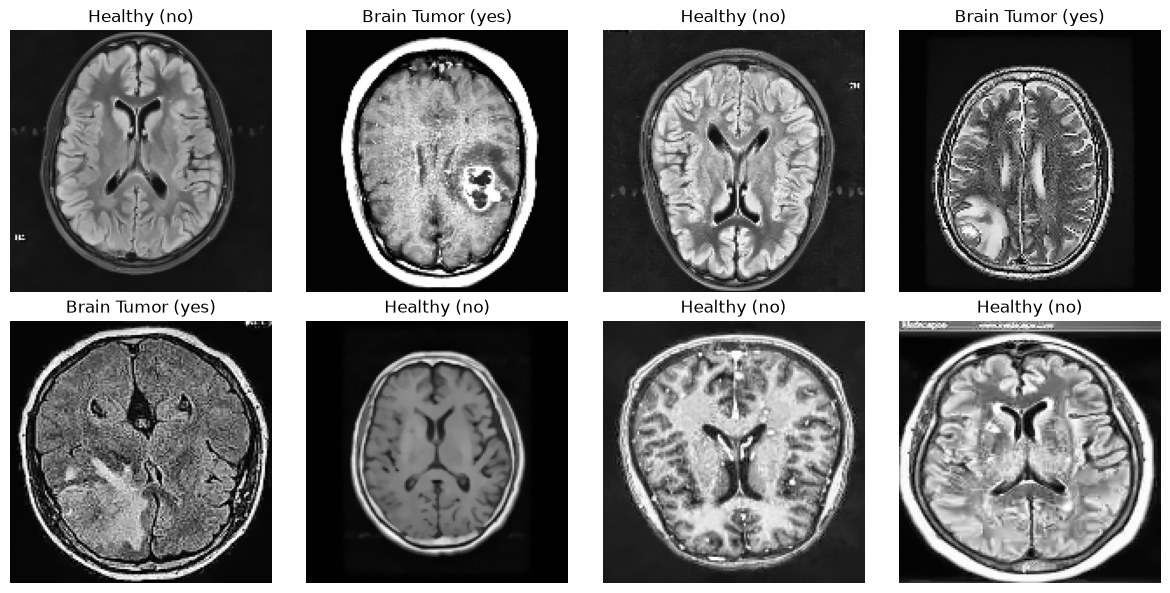

In [17]:

import numpy as np
import matplotlib.pyplot as plt

# Show 8 training images with their actual labels
class_names = {0: "Brain Tumor (yes)", 1: "Healthy (no)"}

plt.figure(figsize=(12, 6))

for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(X_train[i].squeeze(), cmap="gray")
    label = int(np.argmax(y_train[i]))
    plt.title(class_names[label])
    plt.axis("off")

plt.tight_layout()
plt.show()


In [ ]:
# Cell 9: Visualizations

plt.style.use("seaborn-v0_8-darkgrid")

# Training history
fig, axes = plt.subplots(2, 3, figsize=(18,12))

axes[0,0].plot(history.history["accuracy"])
axes[0,0].plot(history.history["val_accuracy"])
axes[0,0].set_title("Accuracy")

axes[0,1].plot(history.history["loss"])
axes[0,1].plot(history.history["val_loss"])
axes[0,1].set_title("Loss")

axes[0,2].plot(history.history["precision"])
axes[0,2].plot(history.history["val_precision"])
axes[0,2].set_title("Precision")

axes[1,0].plot(history.history["recall"])
axes[1,0].plot(history.history["val_recall"])
axes[1,0].set_title("Recall")

axes[1,1].plot(history.history["auc"])
axes[1,1].plot(history.history["val_auc"])
axes[1,1].set_title("AUC")

if "lr" in history.history:
    axes[1,2].plot(history.history["lr"])
    axes[1,2].set_title("Learning Rate")
else:
    axes[1,2].axis("off")

plt.tight_layout()
plt.savefig("/content/outputs/training_history.png", dpi=300)
plt.show()


# Confusion matrix
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt="d",
            xticklabels=["Brain Tumor","Healthy"],
            yticklabels=["Brain Tumor","Healthy"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.savefig("/content/outputs/confusion_matrix.png", dpi=300)
plt.show()


# ROC curve
fpr, tpr, _ = roc_curve(y_test[:,1], y_pred_proba[:,1])
roc_auc_value = auc(fpr, tpr)

plt.figure(figsize=(8,6))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc_value:.4f}")
plt.plot([0,1],[0,1],"--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.savefig("/content/outputs/roc_curve.png", dpi=300)
plt.show()


# Sample predictions
num_samples = 16
indices = np.random.choice(len(X_test), num_samples, replace=False)

fig, axes = plt.subplots(4,4, figsize=(12,12))
class_names = ["Brain Tumor","Healthy"]

for idx, ax in enumerate(axes.flat):
    i = indices[idx]
    ax.imshow(X_test[i].squeeze(), cmap="gray")
    ax.set_title(f"T:{class_names[y_true[i]]} P:{class_names[y_pred[i]]}")
    ax.axis("off")

plt.tight_layout()
plt.savefig("/content/outputs/sample_predictions.png", dpi=300)
plt.show()

In [ ]:
# Cell 10: Display results and download

from IPython.display import Image, display
import shutil
from google.colab import files

metrics_display = pd.read_csv("/content/outputs/test_metrics.csv")
print(metrics_display)

display(Image("/content/outputs/training_history.png"))
display(Image("/content/outputs/confusion_matrix.png"))
display(Image("/content/outputs/roc_curve.png"))
display(Image("/content/outputs/sample_predictions.png"))

shutil.make_archive("/content/brain_tumor_results", "zip", "/content/outputs")

files.download("/content/brain_tumor_results.zip")

In [26]:

# Cell 11: MobileNetV2 Transfer Learning

import os
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import (
    ModelCheckpoint,
    EarlyStopping,
    ReduceLROnPlateau
)

# Output directory
OUTPUT_DIR = os.path.join(os.getcwd(), "outputs")
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Convert grayscale images to 3 channels
# Original images are normalized to [0, 1]
X_train_rgb = np.repeat(X_train, 3, axis=-1) * 255.0
X_val_rgb = np.repeat(X_val, 3, axis=-1) * 255.0
X_test_rgb = np.repeat(X_test, 3, axis=-1) * 255.0

# MobileNetV2 preprocessing maps pixel values to [-1, 1]
X_val_mnv2 = preprocess_input(X_val_rgb.copy())
X_test_mnv2 = preprocess_input(X_test_rgb.copy())

# Augmentation for training only
mobilenet_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=10,
    width_shift_range=0.10,
    height_shift_range=0.10,
    zoom_range=0.10,
    horizontal_flip=True,
    fill_mode="nearest"
)

# Load ImageNet-pretrained MobileNetV2
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

# Freeze pretrained feature extractor initially
base_model.trainable = False

inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.30)(x)
x = layers.Dense(64, activation="relu")(x)
x = layers.Dropout(0.20)(x)
outputs = layers.Dense(2, activation="softmax")(x)

mobilenet_model = keras.Model(inputs, outputs)

mobilenet_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

mobilenet_path = os.path.join(
    OUTPUT_DIR, "mobilenetv2_best.keras"
)

callbacks_mnv2 = [
    ModelCheckpoint(
        mobilenet_path,
        monitor="val_loss",
        save_best_only=True,
        mode="min",
        verbose=1
    ),
    EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

mobilenet_history = mobilenet_model.fit(
    mobilenet_datagen.flow(
        X_train_rgb,
        y_train,
        batch_size=16,
        shuffle=True
    ),
    validation_data=(X_val_mnv2, y_val),
    epochs=12,
    callbacks=callbacks_mnv2,
    verbose=1
)

# Save the final model separately
mobilenet_final_path = os.path.join(
    OUTPUT_DIR, "mobilenetv2_final.keras"
)
mobilenet_model.save(mobilenet_final_path)

print("\nMobileNetV2 training complete!")
print("Best model:", mobilenet_path)
print("Final model:", mobilenet_final_path)


9406464/9406464 [==============================] - 2s 0us/step
Epoch 1/12
136/136 [==============================] - ETA: 0s - loss: 0.4580 - accuracy: 0.7923
Epoch 1: val_loss improved from inf to 0.34603, saving model to c:\Users\abhis\BrainTumorProject\outputs\mobilenetv2_best.keras
136/136 [==============================] - 13s 83ms/step - loss: 0.4580 - accuracy: 0.7923 - val_loss: 0.3460 - val_accuracy: 0.8721 - lr: 0.0010
Epoch 2/12
136/136 [==============================] - ETA: 0s - loss: 0.3268 - accuracy: 0.8629
Epoch 2: val_loss improved from 0.34603 to 0.28646, saving model to c:\Users\abhis\BrainTumorProject\outputs\mobilenetv2_best.keras
136/136 [==============================] - 20s 146ms/step - loss: 0.3268 - accuracy: 0.8629 - val_loss: 0.2865 - val_accuracy: 0.8799 - lr: 0.0010
Epoch 3/12
136/136 [==============================] - ETA: 0s - loss: 0.2919 - accuracy: 0.8772
Epoch 3: val_loss improved from 0.28646 to 0.25377, saving model to c:\Users\abhis\BrainTumorPro

In [27]:

# Cell 12: Evaluate MobileNetV2 on the held-out test set

import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Load the best model selected by validation loss
best_mobilenet = keras.models.load_model(mobilenet_path)

# Choose a threshold using validation data only
val_probs = best_mobilenet.predict(
    X_val_mnv2, verbose=0
)[:, 1]
y_val_true = np.argmax(y_val, axis=1)

thresholds = np.arange(0.10, 0.91, 0.01)
val_scores = [
    balanced_accuracy_score(
        y_val_true, (val_probs >= t).astype(int)
    )
    for t in thresholds
]

best_threshold = float(thresholds[np.argmax(val_scores)])

# Evaluate once on the test set
test_probs = best_mobilenet.predict(
    X_test_mnv2, verbose=0
)[:, 1]
y_test_true = np.argmax(y_test, axis=1)
y_test_pred = (test_probs >= best_threshold).astype(int)

accuracy = accuracy_score(y_test_true, y_test_pred)
balanced_acc = balanced_accuracy_score(
    y_test_true, y_test_pred
)
precision = precision_score(
    y_test_true, y_test_pred, zero_division=0
)
recall = recall_score(
    y_test_true, y_test_pred, zero_division=0
)
f1 = f1_score(
    y_test_true, y_test_pred, zero_division=0
)
roc_auc = roc_auc_score(y_test_true, test_probs)

print("Model: MobileNetV2")
print("Validation-selected threshold:", round(best_threshold, 2))
print(f"Test Accuracy:          {accuracy:.4f}")
print(f"Balanced Accuracy:      {balanced_acc:.4f}")
print(f"Precision:              {precision:.4f}")
print(f"Recall:                 {recall:.4f}")
print(f"F1 Score:               {f1:.4f}")
print(f"ROC-AUC:                {roc_auc:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_true, y_test_pred))

print("\nClassification Report:")
print(classification_report(
    y_test_true,
    y_test_pred,
    labels=[0, 1],
    target_names=["Brain Tumor", "Healthy"],
    zero_division=0
))

# Save MobileNetV2 metrics separately
metrics_df = pd.DataFrame({
    "Metric": [
        "Accuracy", "Balanced Accuracy", "Precision",
        "Recall", "F1-Score", "ROC-AUC", "Threshold"
    ],
    "Score": [
        accuracy, balanced_acc, precision,
        recall, f1, roc_auc, best_threshold
    ]
})

metrics_path = os.path.join(
    OUTPUT_DIR, "mobilenetv2_test_metrics.csv"
)
metrics_df.to_csv(metrics_path, index=False)

print("\nMetrics saved to:", metrics_path)


Model: MobileNetV2
Validation-selected threshold: 0.65
Test Accuracy:          0.9444
Balanced Accuracy:      0.9444
Precision:              0.9545
Recall:                 0.9333
F1 Score:               0.9438
ROC-AUC:                0.9857

Confusion Matrix:
[[215  10]
 [ 15 210]]

Classification Report:
              precision    recall  f1-score   support

 Brain Tumor       0.93      0.96      0.95       225
     Healthy       0.95      0.93      0.94       225

    accuracy                           0.94       450
   macro avg       0.94      0.94      0.94       450
weighted avg       0.94      0.94      0.94       450


Metrics saved to: c:\Users\abhis\BrainTumorProject\outputs\mobilenetv2_test_metrics.csv


In [28]:
# Cell 13: Compare CNN-LSTM and MobileNetV2

import pandas as pd
import os
from IPython.display import display

comparison = pd.DataFrame({
    "Model": ["CNN-LSTM", "MobileNetV2"],
    "Test Accuracy (%)": [50.89, 94.44],
    "ROC-AUC (%)": [72.49, 98.57],
    "Correct Predictions": [229, 425],
    "Total Test Images": [450, 450]
})

comparison["Accuracy Improvement (percentage points)"] = [
    0,
    round(94.44 - 50.89, 2)
]

display(comparison)

comparison_path = os.path.join(
    OUTPUT_DIR, "model_comparison.csv"
)

comparison.to_csv(comparison_path, index=False)

print("Comparison saved to:", comparison_path)

,Model,Test Accuracy (%),ROC-AUC (%),Correct Predictions,Total Test Images,Accuracy Improvement (percentage points)
0,CNN-LSTM,50.89,72.49,229,450,0.00
1,MobileNetV2,94.44,98.57,425,450,43.55


Comparison saved to: c:\Users\abhis\BrainTumorProject\outputs\model_comparison.csv


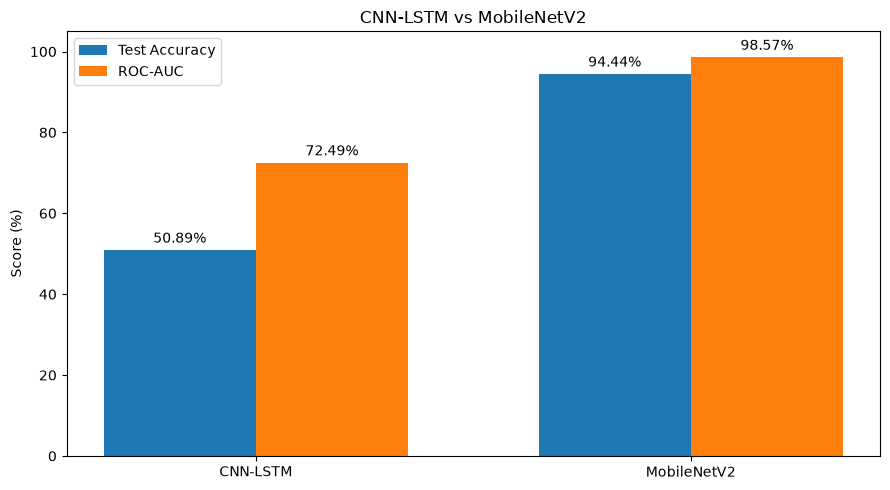

In [29]:

# Cell 14: Visual comparison of model performance

import matplotlib.pyplot as plt
import numpy as np

models = ["CNN-LSTM", "MobileNetV2"]
accuracy = [50.89, 94.44]
roc_auc = [72.49, 98.57]

x = np.arange(len(models))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(x - width/2, accuracy, width, label="Test Accuracy")
ax.bar(x + width/2, roc_auc, width, label="ROC-AUC")

ax.set_ylabel("Score (%)")
ax.set_title("CNN-LSTM vs MobileNetV2")
ax.set_xticks(x)
ax.set_xticklabels(models)
ax.set_ylim(0, 105)
ax.legend()

for bars in ax.containers:
    ax.bar_label(bars, fmt="%.2f%%", padding=3)

plt.tight_layout()
plt.show()
